In [2]:
import sys
import os
import pickle
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils import read_utils
from utils import plot_utils
from utils import train_utils

In [3]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer-(flygenvector)/data_exploration/../utils/train_utils.py'>

In [4]:
# read_ids = list(range(0, 13+1))
read_ids = [3]
plot_id = 3

In [16]:
path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffer-(flygenvector)')

(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# # remove unused discrete state labels
# states = [ds[selection_bhl] for ds in states]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [27]:
# prep

for i, trace in enumerate(traces):
	traces[i] = pd.DataFrame(data=trace.values - np.median(trace.values, axis=0), columns=trace.columns)

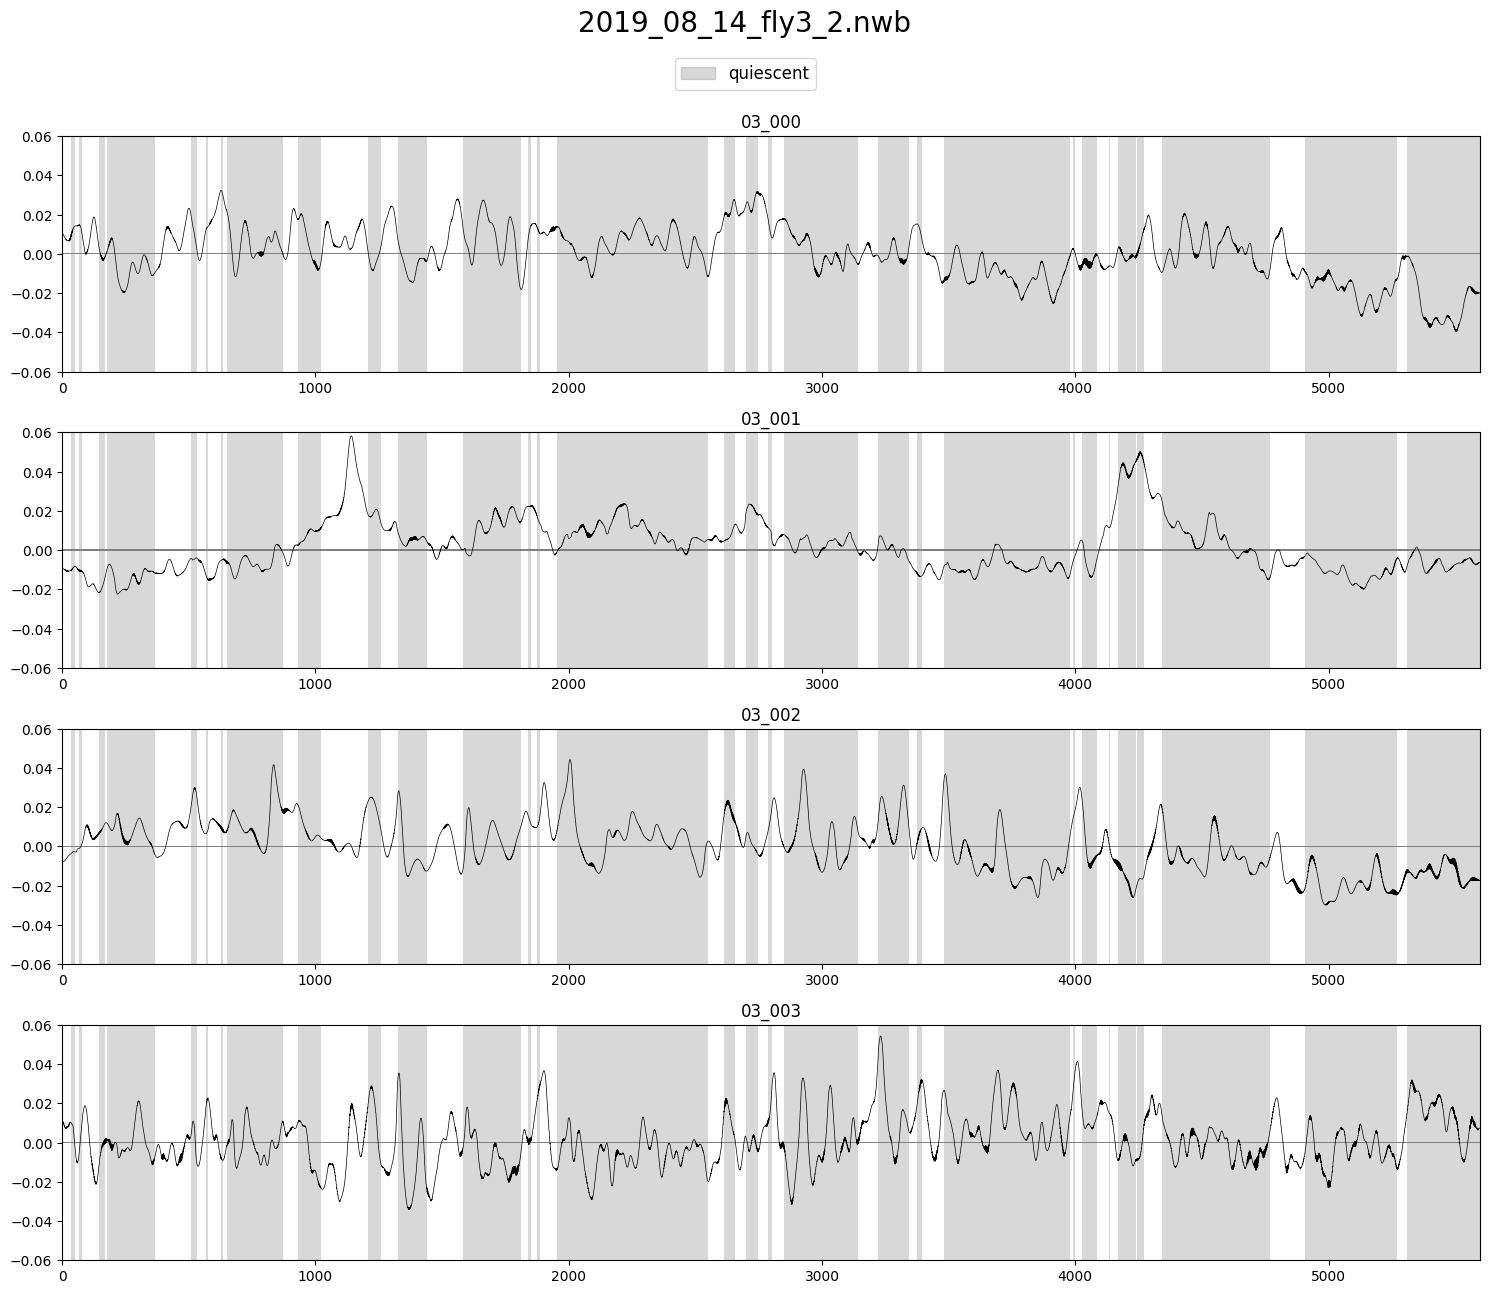

In [28]:
plot_utils.plot_traces(f'{filenames[file_ids.index(plot_id)]}',
					   states[file_ids.index(plot_id)]['still'],
					   [traces[file_ids.index(plot_id)]],
					   label='quiescent', n_plots=4, plots_per_row=1, top_space=1, ylimits=(-0.06, 0.06))

In [29]:
print(np.median(traces[file_ids.index(plot_id)].values, axis=0)[:5])

[0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 1.08420217e-19]
